Learned Weight (Slope): 79.3474
Learned Bias (Intercept): 1.0776
Test Set MSE: 246.1218
Test Set R² Score: 0.9681


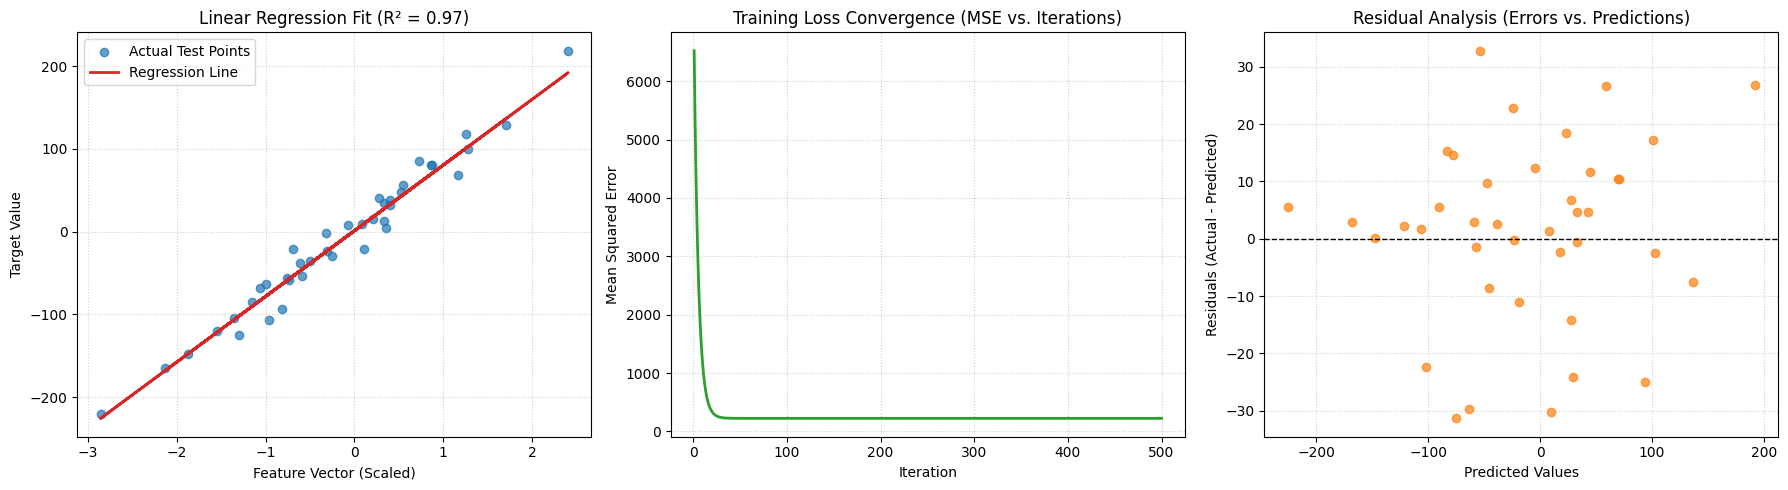

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. Linear Regression Implementation from Scratch
# ============================================================

class LinearRegressionScratch:
    """
    Linear Regression implemented using Gradient Descent.
    Supports both Simple (1D) and Multiple (nD) Linear Regression.
    """
    def __init__(self, learning_rate=0.01, iterations=1000):
        self.lr = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = None
        self.cost_history = []  # Stores MSE loss per iteration

    def fit(self, X, y):
        """
        Fit linear model using Gradient Descent.
        """
        n_samples, n_features = X.shape

        # Initialize parameters: weights = zeros vector, bias = 0
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        # Gradient Descent Optimization Loop
        for _ in range(self.iterations):
            # Step 1: Linear Hypothesis Function (y_hat = X * w + b)
            y_predicted = np.dot(X, self.weights) + self.bias

            # Step 2: Compute Mean Squared Error (MSE) loss
            cost = (1 / n_samples) * np.sum((y_predicted - y) ** 2)
            self.cost_history.append(cost)

            # Step 3: Compute Gradients
            dw = (2 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (2 / n_samples) * np.sum(y_predicted - y)

            # Step 4: Update Parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        """
        Predict target values using the learned weights and bias.
        """
        return np.dot(X, self.weights) + self.bias

    def r2_score(self, X, y):
        """
        Calculate R-squared (R²) Coefficient of Determination score.
        """
        y_pred = self.predict(X)
        ss_total = np.sum((y - np.mean(y)) ** 2)
        ss_residual = np.sum((y - y_pred) ** 2)
        return 1 - (ss_residual / ss_total)

    def mse(self, X, y):
        """
        Calculate Mean Squared Error.
        """
        y_pred = self.predict(X)
        return np.mean((y - y_pred) ** 2)


# ============================================================
# 2. Data Preparation & Scaling
# ============================================================

# Generate synthetic linear data (1 feature for clear visual analysis)
X, y = make_regression(
    n_samples=200,
    n_features=1,
    noise=15,
    random_state=42
)

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features (recommended for gradient descent convergence)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ============================================================
# 3. Model Training & Evaluation
# ============================================================

model = LinearRegressionScratch(learning_rate=0.05, iterations=500)
model.fit(X_train_scaled, y_train)

# Calculate metrics on unseen test set
test_r2 = model.r2_score(X_test_scaled, y_test)
test_mse = model.mse(X_test_scaled, y_test)

print(f"Learned Weight (Slope): {model.weights[0]:.4f}")
print(f"Learned Bias (Intercept): {model.bias:.4f}")
print(f"Test Set MSE: {test_mse:.4f}")
print(f"Test Set R² Score: {test_r2:.4f}")


# ============================================================
# 4. Result Visualizations & Diagnostic Analysis
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Regression Line vs. Actual Test Data
y_pred_test = model.predict(X_test_scaled)
axes[0].scatter(X_test_scaled, y_test, color='#1f77b4', label='Actual Test Points', alpha=0.7)
axes[0].plot(X_test_scaled, y_pred_test, color='#d62728', linewidth=2, label='Regression Line')
axes[0].set_title(f"Linear Regression Fit (R² = {test_r2:.2f})")
axes[0].set_xlabel("Feature Vector (Scaled)")
axes[0].set_ylabel("Target Value")
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()

# Plot 2: Gradient Descent Cost History (Convergence)
axes[1].plot(range(1, len(model.cost_history) + 1), model.cost_history, color='#2ca02c', linewidth=2)
axes[1].set_title("Training Loss Convergence (MSE vs. Iterations)")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Mean Squared Error")
axes[1].grid(True, linestyle=':', alpha=0.6)

# Plot 3: Residual Plot (Actual vs. Error)
residuals = y_test - y_pred_test
axes[2].scatter(y_pred_test, residuals, color='#ff7f0e', alpha=0.7)
axes[2].axhline(y=0, color='k', linestyle='--', linewidth=1)
axes[2].set_title("Residual Analysis (Errors vs. Predictions)")
axes[2].set_xlabel("Predicted Values")
axes[2].set_ylabel("Residuals (Actual - Predicted)")
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Lambda = 0.0   | Test MSE: 900.59   | Test R²: 0.8240 | Weight Norm (||w||): 48.9547
Lambda = 0.1   | Test MSE: 909.02   | Test R²: 0.8224 | Weight Norm (||w||): 44.5360
Lambda = 1.0   | Test MSE: 1848.60  | Test R²: 0.6388 | Weight Norm (||w||): 24.8916
Lambda = 10.0  | Test MSE: 4338.39  | Test R²: 0.1524 | Weight Norm (||w||): 4.7051
Lambda = 100.0 | Test MSE: nan      | Test R²: nan | Weight Norm (||w||): nan


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/tmp/ipykernel_5819/4044795787.py:37: RuntimeWarning: overflow encountered in scalar multiply
  l2_cost = self.l2_penalty * np.sum(self.weights ** 2)
/tmp/ipykernel_5819/4044795787.py:36: RuntimeWarning: overflow encountered in square
  mse_cost = (1 / n_samples) * np.sum((y_predicted - y) ** 2)
/tmp/ipykernel_5819/4044795787.py:37: RuntimeWarning: overflow encountered in square
  l2_cost = self.l2_penalty * np.sum(self.weights ** 2)
/tmp/ipykernel_5819/4044795787.py:43: RuntimeWarning: overflow encountered in multiply
  dw = (2 / n_samples) * np.dot(X.T, (y_predicted - y)) + (2 * self.l2_penalty * self.weights)
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/usr/local/lib/python

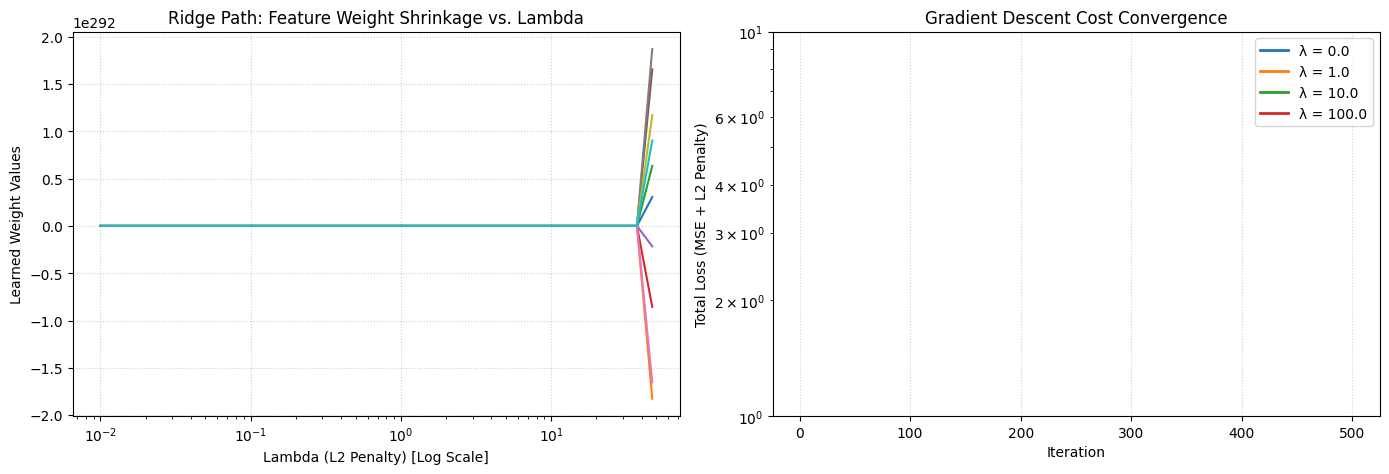

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. Ridge Regression (L2 Regularization) Implementation
# ============================================================

class RidgeRegressionScratch:
    """
    Linear Regression with L2 Regularization (Ridge Regression) using Gradient Descent.
    Loss Function: MSE + lambda * sum(weights^2)
    """
    def __init__(self, l2_penalty=1.0, learning_rate=0.01, iterations=1000):
        self.l2_penalty = l2_penalty  # Regularization parameter (lambda)
        self.lr = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = None
        self.cost_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape

        # Initialize parameters
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for _ in range(self.iterations):
            # Step 1: Linear Hypothesis (y_hat = X * w + b)
            y_predicted = np.dot(X, self.weights) + self.bias

            # Step 2: Compute Cost with L2 Penalty: MSE + lambda * ||w||^2
            mse_cost = (1 / n_samples) * np.sum((y_predicted - y) ** 2)
            l2_cost = self.l2_penalty * np.sum(self.weights ** 2)
            total_cost = mse_cost + l2_cost
            self.cost_history.append(total_cost)

            # Step 3: Compute Gradients (Note: L2 adds 2 * lambda * w to weights gradient)
            # Bias is intentionally NOT regularized.
            dw = (2 / n_samples) * np.dot(X.T, (y_predicted - y)) + (2 * self.l2_penalty * self.weights)
            db = (2 / n_samples) * np.sum(y_predicted - y)

            # Step 4: Update Parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

    def r2_score(self, X, y):
        y_pred = self.predict(X)
        ss_total = np.sum((y - np.mean(y)) ** 2)
        ss_residual = np.sum((y - y_pred) ** 2)
        return 1 - (ss_residual / ss_total)

    def mse(self, X, y):
        y_pred = self.predict(X)
        return np.mean((y - y_pred) ** 2)


# ============================================================
# 2. Dataset Generation (Multicollinear & Noisy)
# ============================================================

# Generate synthetic dataset with correlated/noisy features to demonstrate regularization
X, y = make_regression(
    n_samples=200,
    n_features=10,
    n_informative=4,
    noise=25,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ============================================================
# 3. Model Training & Comparison Across Lambda Values
# ============================================================

lambdas = [0.0, 0.1, 1.0, 10.0, 100.0]
results = {}

for l2_val in lambdas:
    ridge = RidgeRegressionScratch(l2_penalty=l2_val, learning_rate=0.05, iterations=500)
    ridge.fit(X_train_scaled, y_train)

    test_r2 = ridge.r2_score(X_test_scaled, y_test)
    test_mse = ridge.mse(X_test_scaled, y_test)

    results[l2_val] = {
        'model': ridge,
        'r2': test_r2,
        'mse': test_mse,
        'weight_norm': np.linalg.norm(ridge.weights)  # Magnitude of weights
    }
    print(f"Lambda = {l2_val:<5} | Test MSE: {test_mse:<8.2f} | Test R²: {test_r2:.4f} | Weight Norm (||w||): {results[l2_val]['weight_norm']:.4f}")


# ============================================================
# 4. Visual Analysis: Effect of L2 Penalty (Lambda)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Weight Shrinkage Path (Effect of Lambda on Coefficient Magnitudes)
lambda_range = np.logspace(-2, 3, 50)
weights_path = []

for l2_val in lambda_range:
    r_model = RidgeRegressionScratch(l2_penalty=l2_val, learning_rate=0.05, iterations=500)
    r_model.fit(X_train_scaled, y_train)
    weights_path.append(r_model.weights)

weights_path = np.array(weights_path)

for feature_idx in range(weights_path.shape[1]):
    axes[0].plot(lambda_range, weights_path[:, feature_idx], label=f'Feature {feature_idx+1}')

axes[0].set_xscale('log')
axes[0].set_title("Ridge Path: Feature Weight Shrinkage vs. Lambda")
axes[0].set_xlabel("Lambda (L2 Penalty) [Log Scale]")
axes[0].set_ylabel("Learned Weight Values")
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot 2: Cost Function Convergence for Selected Lambdas
for l2_val in [0.0, 1.0, 10.0, 100.0]:
    axes[1].plot(
        range(1, 501),
        results[l2_val]['model'].cost_history,
        linewidth=2,
        label=f'λ = {l2_val}'
    )

axes[1].set_title("Gradient Descent Cost Convergence")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Total Loss (MSE + L2 Penalty)")
axes[1].set_yscale('log')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

Lambda = 0.01  | Test MSE: 213.71   | Test R²: 0.8907 | Zeroed Weights (Sparsity): 0/10
Lambda = 0.5   | Test MSE: 202.28   | Test R²: 0.8966 | Zeroed Weights (Sparsity): 2/10
Lambda = 2.0   | Test MSE: 194.56   | Test R²: 0.9005 | Zeroed Weights (Sparsity): 7/10
Lambda = 5.0   | Test MSE: 221.93   | Test R²: 0.8865 | Zeroed Weights (Sparsity): 7/10
Lambda = 15.0  | Test MSE: 421.79   | Test R²: 0.7843 | Zeroed Weights (Sparsity): 8/10


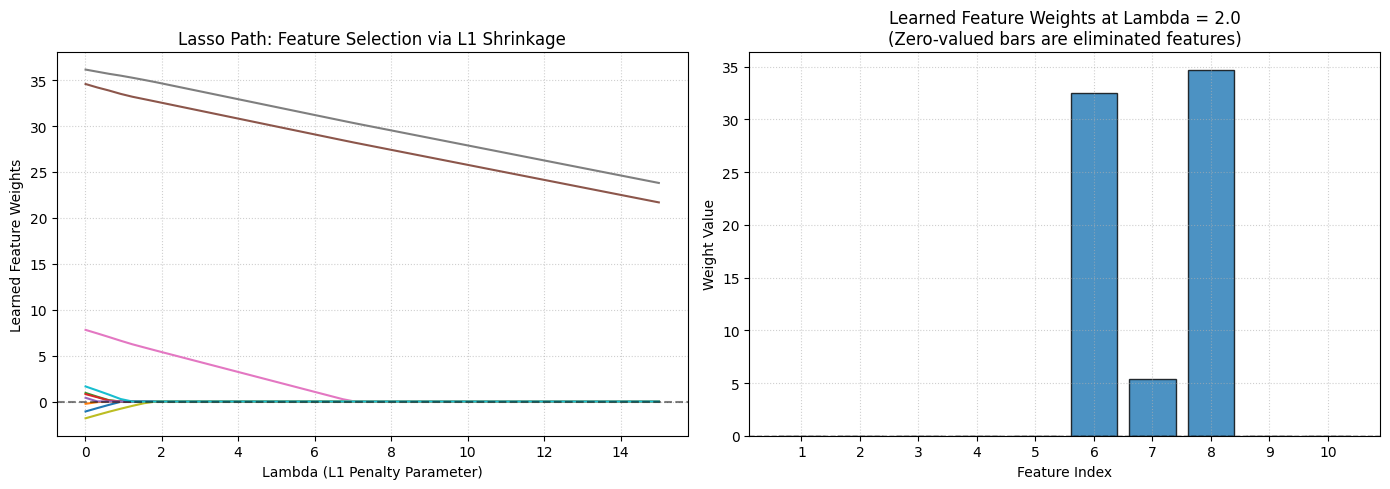

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. Lasso Regression (L1 Regularization) Implementation
# ============================================================

class LassoRegressionScratch:
    """
    Linear Regression with L1 Regularization (Lasso) using Coordinate Descent.

    Objective Function:
    Loss = (1 / (2 * n)) * ||y - X*w||^2 + lambda * ||w||_1
    """
    def __init__(self, l1_penalty=1.0, max_iter=1000, tol=1e-4):
        self.l1_penalty = l1_penalty  # Regularization parameter (lambda)
        self.max_iter = max_iter      # Maximum full passes over features
        self.tol = tol                # Convergence tolerance threshold
        self.weights = None
        self.bias = 0.0
        self.cost_history = []

    def _soft_threshold(self, rho, l1_val):
        """
        Soft-thresholding operator S(rho, lambda):
        S(rho, lambda) = sign(rho) * max(0, |rho| - lambda)
        """
        if rho < -l1_val:
            return rho + l1_val
        elif rho > l1_val:
            return rho - l1_val
        else:
            return 0.0

    def fit(self, X, y):
        n_samples, n_features = X.shape

        # Center target variable and calculate bias term
        self.bias = np.mean(y)
        y_centered = y - self.bias

        # Initialize weight vector to zeros
        self.weights = np.zeros(n_features)

        # Precompute normalized feature squared norms: sum(X_j^2) / n_samples
        feature_norms = np.sum(X ** 2, axis=0) / n_samples

        for iteration in range(self.max_iter):
            weights_old = self.weights.copy()

            # Pass 1: Coordinate Descent Step across every feature index
            for j in range(n_features):
                # Calculate partial residual excluding feature j
                y_pred_excl_j = np.dot(X, self.weights) - (X[:, j] * self.weights[j])
                residual = y_centered - y_pred_excl_j

                # Correlation term between feature j and partial residual
                rho_j = np.dot(X[:, j], residual) / n_samples

                # Update j-th weight using soft-threshold operator
                if feature_norms[j] > 0:
                    self.weights[j] = self._soft_threshold(rho_j, self.l1_penalty) / feature_norms[j]
                else:
                    self.weights[j] = 0.0

            # Step 2: Calculate total objective function (MSE / 2 + lambda * L1_norm)
            y_pred = np.dot(X, self.weights) + self.bias
            mse_loss = (1 / (2 * n_samples)) * np.sum((y - y_pred) ** 2)
            l1_loss = self.l1_penalty * np.sum(np.abs(self.weights))
            self.cost_history.append(mse_loss + l1_loss)

            # Step 3: Check for convergence
            if np.max(np.abs(self.weights - weights_old)) < self.tol:
                break

    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

    def r2_score(self, X, y):
        y_pred = self.predict(X)
        ss_total = np.sum((y - np.mean(y)) ** 2)
        ss_residual = np.sum((y - y_pred) ** 2)
        return 1 - (ss_residual / ss_total)

    def mse(self, X, y):
        y_pred = self.predict(X)
        return np.mean((y - y_pred) ** 2)


# ============================================================
# 2. Dataset Synthesis (Sparse Feature Environment)
# ============================================================

# Synthetic dataset: 10 features total, but ONLY 3 are genuinely informative
X, y = make_regression(
    n_samples=200,
    n_features=10,
    n_informative=3,
    noise=15,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ============================================================
# 3. Model Training & Comparison Across Lambda Values
# ============================================================

lambdas = [0.01, 0.5, 2.0, 5.0, 15.0]
results = {}

for l1_val in lambdas:
    lasso = LassoRegressionScratch(l1_penalty=l1_val, max_iter=1000)
    lasso.fit(X_train_scaled, y_train)

    test_r2 = lasso.r2_score(X_test_scaled, y_test)
    test_mse = lasso.mse(X_test_scaled, y_test)
    zero_weights = np.sum(lasso.weights == 0)

    results[l1_val] = {
        'model': lasso,
        'r2': test_r2,
        'mse': test_mse,
        'zero_weights': zero_weights
    }
    print(f"Lambda = {l1_val:<5} | Test MSE: {test_mse:<8.2f} | Test R²: {test_r2:.4f} | Zeroed Weights (Sparsity): {zero_weights}/10")


# ============================================================
# 4. Diagnostic Visualization: Feature Selection Analysis
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Lasso Path (Feature Weights set directly to 0 as Lambda increases)
lambda_range = np.linspace(0.01, 15.0, 50)
weights_path = []

for l1_val in lambda_range:
    l_model = LassoRegressionScratch(l1_penalty=l1_val, max_iter=500)
    l_model.fit(X_train_scaled, y_train)
    weights_path.append(l_model.weights)

weights_path = np.array(weights_path)

for feature_idx in range(weights_path.shape[1]):
    axes[0].plot(lambda_range, weights_path[:, feature_idx], label=f'Feature {feature_idx+1}')

axes[0].axhline(y=0, color='k', linestyle='--', alpha=0.5)
axes[0].set_title("Lasso Path: Feature Selection via L1 Shrinkage")
axes[0].set_xlabel("Lambda (L1 Penalty Parameter)")
axes[0].set_ylabel("Learned Feature Weights")
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot 2: Final Learned Coefficients at Lambda = 2.0
best_lasso = results[2.0]['model']
feature_indices = np.arange(1, 11)

axes[1].bar(feature_indices, best_lasso.weights, color='#1f77b4', edgecolor='black', alpha=0.8)
axes[1].axhline(y=0, color='k', linestyle='--', linewidth=1)
axes[1].set_title("Learned Feature Weights at Lambda = 2.0\n(Zero-valued bars are eliminated features)")
axes[1].set_xlabel("Feature Index")
axes[1].set_ylabel("Weight Value")
axes[1].set_xticks(feature_indices)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

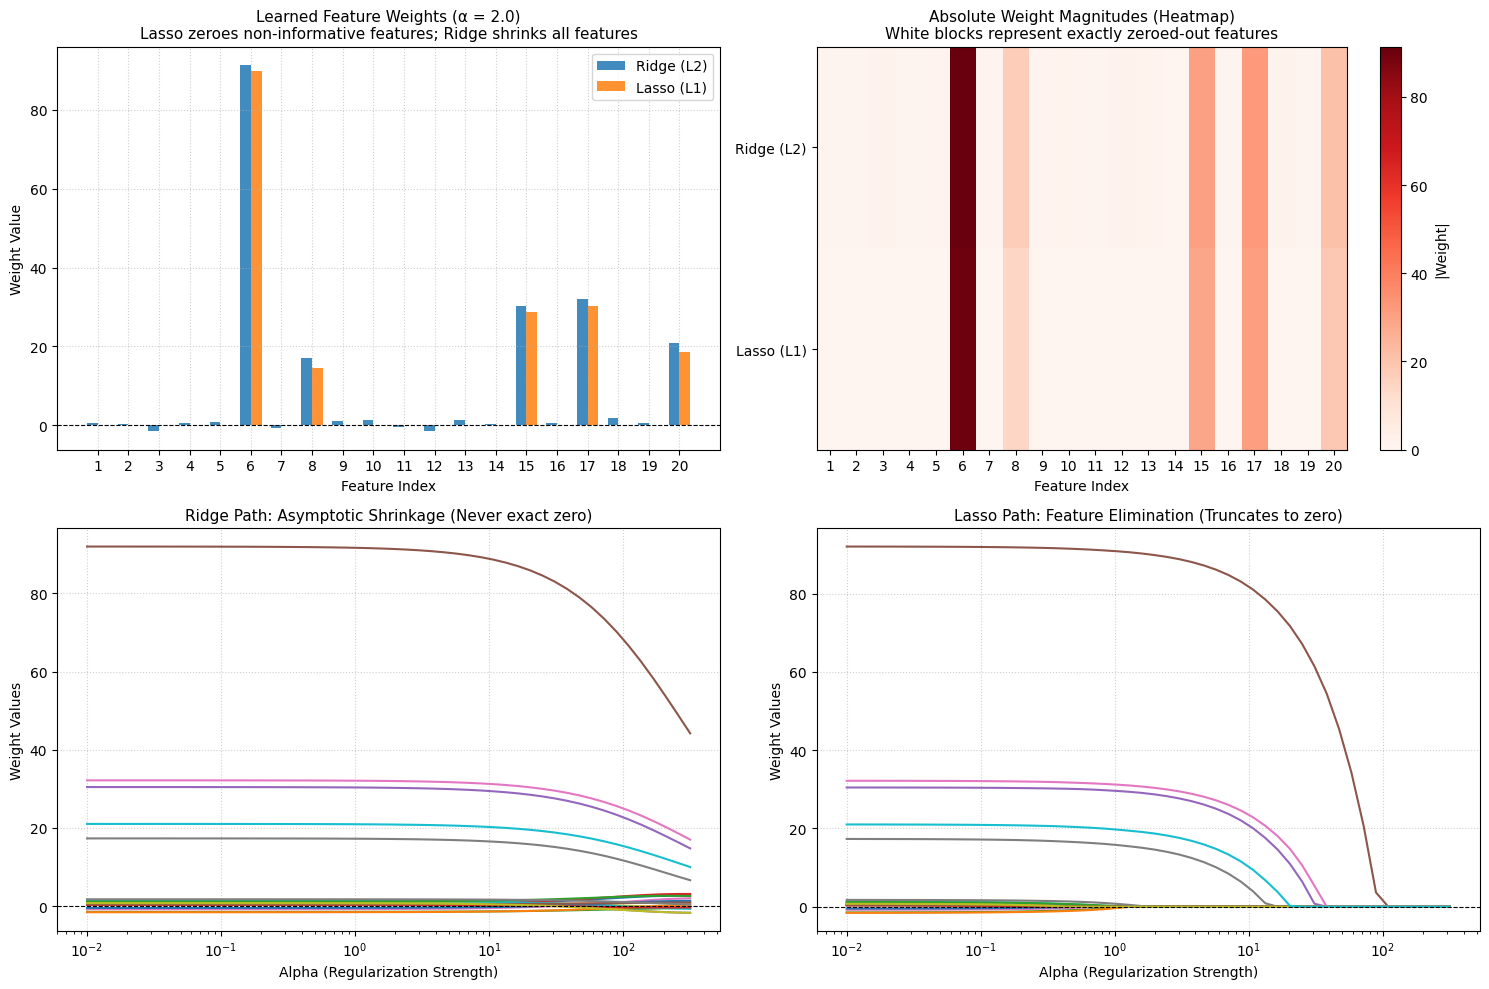

Total Features in Dataset: 20 (Only 5 are informative)
Ridge Active (Non-zero) Features: 20 / 20
Lasso Active (Non-zero) Features: 5 / 20


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. Dataset Generation (20 Features, Only 5 Truly Informative)
# ============================================================

X, y = make_regression(
    n_samples=300,
    n_features=20,
    n_informative=5,
    noise=15,
    random_state=42
)

# Feature scaling is required for fair regularized weight comparisons
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# ============================================================
# 2. Model Fitting across Regularization Strengths (Alphas)
# ============================================================

# Model evaluation at a specific penalty value
alpha_val = 2.0
ridge = Ridge(alpha=alpha_val, random_state=42)
lasso = Lasso(alpha=alpha_val, random_state=42)

ridge.fit(X_scaled, y)
lasso.fit(X_scaled, y)

# Path analysis across varying penalty parameters
alphas = np.logspace(-2, 2.5, 50)
ridge_path = []
lasso_path = []

for a in alphas:
    r_model = Ridge(alpha=a, random_state=42).fit(X_scaled, y)
    l_model = Lasso(alpha=a, random_state=42).fit(X_scaled, y)
    ridge_path.append(r_model.coef_)
    lasso_path.append(l_model.coef_)

ridge_path = np.array(ridge_path)
lasso_path = np.array(lasso_path)


# ============================================================
# 3. Visualization: Ridge vs. Lasso Sparsity Comparison
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

feature_indices = np.arange(1, 21)

# Plot 1: Direct Bar Comparison of Coefficients (Ridge vs. Lasso)
width = 0.35
axes[0, 0].bar(feature_indices - width/2, ridge.coef_, width, label='Ridge (L2)', color='#1f77b4', alpha=0.85)
axes[0, 0].bar(feature_indices + width/2, lasso.coef_, width, label='Lasso (L1)', color='#ff7f0e', alpha=0.85)
axes[0, 0].axhline(y=0, color='black', linestyle='--', linewidth=0.8)
axes[0, 0].set_title(f"Learned Feature Weights (α = {alpha_val})\nLasso zeroes non-informative features; Ridge shrinks all features", fontsize=11)
axes[0, 0].set_xlabel("Feature Index")
axes[0, 0].set_ylabel("Weight Value")
axes[0, 0].set_xticks(feature_indices)
axes[0, 0].grid(True, linestyle=':', alpha=0.6)
axes[0, 0].legend()

# Plot 2: Weight Magnitude Heatmap (Sparsity Check)
weights_matrix = np.vstack([ridge.coef_, lasso.coef_])
im = axes[0, 1].imshow(np.abs(weights_matrix), cmap='Reds', aspect='auto')
axes[0, 1].set_yticks([0, 1])
axes[0, 1].set_yticklabels(['Ridge (L2)', 'Lasso (L1)'])
axes[0, 1].set_xticks(range(20))
axes[0, 1].set_xticklabels(feature_indices)
axes[0, 1].set_title("Absolute Weight Magnitudes (Heatmap)\nWhite blocks represent exactly zeroed-out features", fontsize=11)
axes[0, 1].set_xlabel("Feature Index")
fig.colorbar(im, ax=axes[0, 1], orientation='vertical', label='|Weight|')

# Plot 3: Ridge Coefficient Path across Alphas
for f_idx in range(20):
    axes[1, 0].plot(alphas, ridge_path[:, f_idx], linewidth=1.5)
axes[1, 0].set_xscale('log')
axes[1, 0].axhline(y=0, color='black', linestyle='--', linewidth=0.8)
axes[1, 0].set_title("Ridge Path: Asymptotic Shrinkage (Never exact zero)", fontsize=11)
axes[1, 0].set_xlabel("Alpha (Regularization Strength)")
axes[1, 0].set_ylabel("Weight Values")
axes[1, 0].grid(True, linestyle=':', alpha=0.6)

# Plot 4: Lasso Coefficient Path across Alphas
for f_idx in range(20):
    axes[1, 1].plot(alphas, lasso_path[:, f_idx], linewidth=1.5)
axes[1, 1].set_xscale('log')
axes[1, 1].axhline(y=0, color='black', linestyle='--', linewidth=0.8)
axes[1, 1].set_title("Lasso Path: Feature Elimination (Truncates to zero)", fontsize=11)
axes[1, 1].set_xlabel("Alpha (Regularization Strength)")
axes[1, 1].set_ylabel("Weight Values")
axes[1, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Print Sparsity Summary
print(f"Total Features in Dataset: 20 (Only 5 are informative)")
print(f"Ridge Active (Non-zero) Features: {np.sum(np.abs(ridge.coef_) > 1e-4)} / 20")
print(f"Lasso Active (Non-zero) Features: {np.sum(np.abs(lasso.coef_) > 1e-4)} / 20")

l1_ratio   | Model Type      | Test MSE   | Test R²  | Sparsity (Zeros)  
---------------------------------------------------------------------------
0.00       | Ridge (L2)      | 12545.18   | 0.4552   | 0/12 weights zeroed
0.25       | ElasticNet      | 10571.85   | 0.5409   | 0/12 weights zeroed
0.50       | ElasticNet      | 7901.42    | 0.6569   | 0/12 weights zeroed
0.75       | ElasticNet      | 4257.90    | 0.8151   | 2/12 weights zeroed
1.00       | Lasso (L1)      | 546.60     | 0.9763   | 6/12 weights zeroed


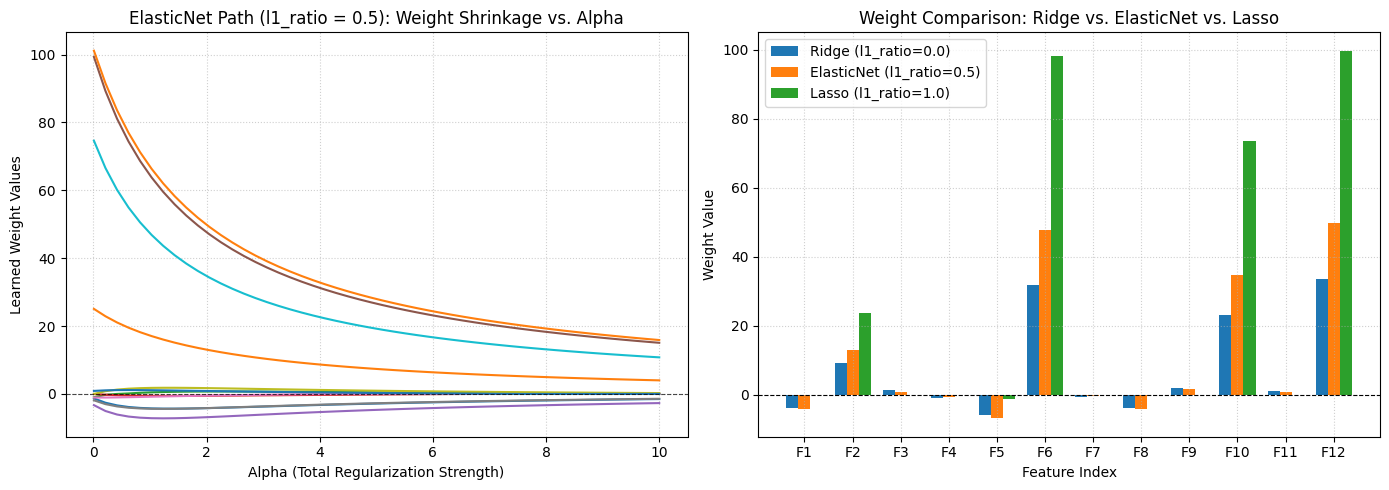

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. ElasticNet Regression Implementation from Scratch
# ============================================================

class ElasticNetScratch:
    """
    ElasticNet Regression using Coordinate Descent.

    Objective Function:
    Min (1 / (2 * n_samples)) * ||y - X w - b||^2
        + alpha * l1_ratio * ||w||_1
        + 0.5 * alpha * (1 - l1_ratio) * ||w||_2^2
    """
    def __init__(self, alpha=1.0, l1_ratio=0.5, max_iter=1000, tol=1e-4):
        self.alpha = alpha          # Total regularization penalty strength
        self.l1_ratio = l1_ratio    # Mixing parameter: 1 = Lasso (L1), 0 = Ridge (L2)
        self.max_iter = max_iter
        self.tol = tol
        self.weights = None
        self.bias = None
        self.cost_history = []

    def _soft_thresholding(self, rho, l1_penalty):
        """
        Soft-Thresholding Operator: S(rho, lambda_1)
        Enforces exact zero weight values for feature selection.
        """
        if rho < -l1_penalty:
            return rho + l1_penalty
        elif rho > l1_penalty:
            return rho - l1_penalty
        else:
            return 0.0

    def fit(self, X, y):
        """
        Fit ElasticNet model using Cyclic Coordinate Descent.
        """
        n_samples, n_features = X.shape

        # Calculate separate L1 and L2 penalty coefficients
        l1_penalty = self.alpha * self.l1_ratio
        l2_penalty = self.alpha * (1.0 - self.l1_ratio)

        # Initialize parameters
        self.weights = np.zeros(n_features)
        self.bias = np.mean(y)

        # Coordinate Descent Optimization Loop
        for iteration in range(self.max_iter):
            weights_old = self.weights.copy()
            y_centered = y - self.bias

            # Update each weight coordinate sequentially
            for j in range(n_features):
                # Calculate partial prediction excluding feature j
                y_pred_excl_j = np.dot(X, self.weights) - (X[:, j] * self.weights[j])

                # Compute correlation between residual and feature j
                rho = np.dot(X[:, j], y_centered - y_pred_excl_j) / n_samples

                # Calculate feature variance component z_j = (1 / n_samples) * sum(x_ij^2)
                z_j = np.sum(X[:, j] ** 2) / n_samples

                # ElasticNet Weight Update Equation
                # Numerator: Soft-thresholding applied to L1 component
                # Denominator: Scale factor including L2 penalty component
                if z_j + l2_penalty > 0:
                    self.weights[j] = self._soft_thresholding(rho, l1_penalty) / (z_j + l2_penalty)
                else:
                    self.weights[j] = 0.0

            # Update bias (intercept remains unregularized)
            self.bias = np.mean(y - np.dot(X, self.weights))

            # Compute Objective Loss: MSE + L1_penalty + L2_penalty
            residuals = y - (np.dot(X, self.weights) + self.bias)
            mse_loss = (1 / (2 * n_samples)) * np.sum(residuals ** 2)
            l1_loss = l1_penalty * np.sum(np.abs(self.weights))
            l2_loss = 0.5 * l2_penalty * np.sum(self.weights ** 2)
            total_loss = mse_loss + l1_loss + l2_loss
            self.cost_history.append(total_loss)

            # Check convergence
            if np.max(np.abs(self.weights - weights_old)) < self.tol:
                break

    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

    def r2_score(self, X, y):
        y_pred = self.predict(X)
        ss_total = np.sum((y - np.mean(y)) ** 2)
        ss_residual = np.sum((y - y_pred) ** 2)
        return 1 - (ss_residual / ss_total)

    def mse(self, X, y):
        y_pred = self.predict(X)
        return np.mean((y - y_pred) ** 2)


# ============================================================
# 2. Dataset Synthesis (Multicollinear & Sparse Signal)
# ============================================================

# Generate dataset with 12 features, correlated features, and noise
X, y = make_regression(
    n_samples=250,
    n_features=12,
    n_informative=4,
    noise=20,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ============================================================
# 3. Model Training & Comparison across L1 Ratios
# ============================================================

l1_ratios = [0.0, 0.25, 0.5, 0.75, 1.0]  # 0.0 = Ridge, 1.0 = Lasso
alpha_val = 2.0
results = {}

print(f"{'l1_ratio':<10} | {'Model Type':<15} | {'Test MSE':<10} | {'Test R²':<8} | {'Sparsity (Zeros)':<18}")
print("-" * 75)

for ratio in l1_ratios:
    model_type = "Ridge (L2)" if ratio == 0.0 else ("Lasso (L1)" if ratio == 1.0 else "ElasticNet")

    enet = ElasticNetScratch(alpha=alpha_val, l1_ratio=ratio, max_iter=1000)
    enet.fit(X_train_scaled, y_train)

    test_r2 = enet.r2_score(X_test_scaled, y_test)
    test_mse = enet.mse(X_test_scaled, y_test)
    zero_weights = np.sum(enet.weights == 0)

    results[ratio] = {
        'model': enet,
        'r2': test_r2,
        'mse': test_mse,
        'zero_weights': zero_weights
    }

    print(f"{ratio:<10.2f} | {model_type:<15} | {test_mse:<10.2f} | {test_r2:<8.4f} | {zero_weights}/12 weights zeroed")


# ============================================================
# 4. Result Visualizations & Analysis
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: ElasticNet Path (Effect of alpha on weights at l1_ratio = 0.5)
alphas = np.linspace(0.01, 10.0, 50)
weights_path = []

for a in alphas:
    m = ElasticNetScratch(alpha=a, l1_ratio=0.5, max_iter=500)
    m.fit(X_train_scaled, y_train)
    weights_path.append(m.weights)

weights_path = np.array(weights_path)

for feature_idx in range(weights_path.shape[1]):
    axes[0].plot(alphas, weights_path[:, feature_idx], label=f'Feature {feature_idx+1}')

axes[0].axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
axes[0].set_title("ElasticNet Path (l1_ratio = 0.5): Weight Shrinkage vs. Alpha")
axes[0].set_xlabel("Alpha (Total Regularization Strength)")
axes[0].set_ylabel("Learned Weight Values")
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot 2: Weight Spectrum Across Regularization Types
x_indices = np.arange(X_train.shape[1])
bar_width = 0.25

axes[1].bar(x_indices - bar_width, results[0.0]['model'].weights, width=bar_width, label='Ridge (l1_ratio=0.0)')
axes[1].bar(x_indices, results[0.5]['model'].weights, width=bar_width, label='ElasticNet (l1_ratio=0.5)')
axes[1].bar(x_indices + bar_width, results[1.0]['model'].weights, width=bar_width, label='Lasso (l1_ratio=1.0)')

axes[1].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[1].set_title("Weight Comparison: Ridge vs. ElasticNet vs. Lasso")
axes[1].set_xlabel("Feature Index")
axes[1].set_ylabel("Weight Value")
axes[1].set_xticks(x_indices)
axes[1].set_xticklabels([f"F{i+1}" for i in range(X_train.shape[1])])
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()